# 混合网络：把量子电路当作普通层

学习一个简单关系 `y = 0.5x₀ − 0.3x₁`。网络结构是 `Linear → PQC → Linear`；输入、量子角度和经典权重都能通过同一次 `loss.backward()` 求梯度。

In [1]:
from qutai import Stream, nn, qnn, visualization
device = "apple"

## 1. 准备数据

九对小数字组成一个完整批次。和经典网络一样，`Stream` 负责分批和设备转换。

In [2]:
inputs = [[a, b] for a in (-1, 0, 1) for b in (-1, 0, 1)]
targets = [[0.5 * a - 0.3 * b] for a, b in inputs]
data = Stream(inputs, targets, batch_size=9, device=device, progress=False)

## 2. 放入量子层

`PQC(2)` 接收两个实数，使用两个量子比特，输出两个可求导的期望值。旋转门的种类在创建时随机选择并固定，训练只更新角度。

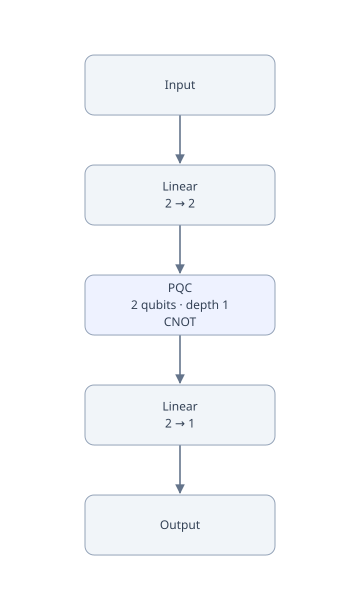

In [3]:
model = nn.Model([
    nn.Linear(2, 2),
    qnn.PQC(2, depth=1),  # 输入两个角度，输出两个量子特征。
    nn.Linear(2, 1),
]).to(device)
optimizer = nn.AdamW(model, learning_rate=0.03)
loss_function = nn.MSE()
visualization.Network(model)

这就是第二层为一个样本搭出的实际电路。前面的 Linear 先把原始输入变成两个编码角度。

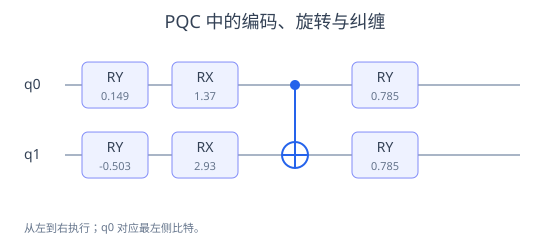

In [4]:
features = model.layers[0](inputs)[0]
visualization.Circuit(model.layers[1].circuit(features), title="PQC 中的编码、旋转与纠缠")

## 3. 使用同一套训练循环

这里与回归、分类的训练写法完全相同，不需要单独调用量子求导。每一轮遍历一次数据。

In [5]:
epochs = 50
# 每轮遍历一次数据；每批独立完成一次参数更新。
for epoch in range(epochs):
    for inputs, targets in data:
        optimizer.zero_grad()
        loss = loss_function(model(inputs), targets)
        loss.backward()
        optimizer.step()
    print(f"epoch {epoch + 1}/{epochs}  loss {loss.item():.4f}")

epoch 1/50  loss 0.3089
epoch 2/50  loss 0.2929
epoch 3/50  loss 0.2803
epoch 4/50  loss 0.2684
epoch 5/50  loss 0.2577
epoch 6/50  loss 0.2484
epoch 7/50  loss 0.2404
epoch 8/50  loss 0.2334
epoch 9/50  loss 0.2270
epoch 10/50  loss 0.2209
epoch 11/50  loss 0.2150
epoch 12/50  loss 0.2091
epoch 13/50  loss 0.2030
epoch 14/50  loss 0.1962
epoch 15/50  loss 0.1886
epoch 16/50  loss 0.1797
epoch 17/50  loss 0.1694
epoch 18/50  loss 0.1578
epoch 19/50  loss 0.1451
epoch 20/50  loss 0.1315
epoch 21/50  loss 0.1173
epoch 22/50  loss 0.1027
epoch 23/50  loss 0.0880
epoch 24/50  loss 0.0735
epoch 25/50  loss 0.0598
epoch 26/50  loss 0.0474
epoch 27/50  loss 0.0367
epoch 28/50  loss 0.0281
epoch 29/50  loss 0.0217
epoch 30/50  loss 0.0175
epoch 31/50  loss 0.0150
epoch 32/50  loss 0.0139
epoch 33/50  loss 0.0135
epoch 34/50  loss 0.0133
epoch 35/50  loss 0.0131
epoch 36/50  loss 0.0125
epoch 37/50  loss 0.0116
epoch 38/50  loss 0.0105
epoch 39/50  loss 0.0090
epoch 40/50  loss 0.0074
epoch 41/

## 4. 试几个输入

每次初始化不同，短训练的结果也不同。这里主要展示量子层怎样接进普通模型，并不表示量子模型优于经典模型。

In [6]:
inputs = [[1, -1], [0, 0], [-1, 1]]
targets = [[0.8], [0], [-0.8]]
predictions = model(inputs, train=False).tolist()
visualization.Table([[*sample, target[0], prediction[0]] for sample, target, prediction in zip(inputs, targets, predictions)], columns=["x₀", "x₁", "目标", "预测"])

x₀,x₁,目标,预测
1,-1,0.8,0.7290353178977966
0,0,0,-0.022502198815345764
-1,1,-0.8,-0.6390005350112915
